# 07 · SHAP explanations (Stage 3)
**Goal:** show *why* the LightGBM P50 model forecasts what it does, and how that changes with horizon.

- Models: the realistic `lagged` LightGBM P50 models, refitted from the tuned parameters in `reports/lgbm_params.json` (notebook 05).
- Horizons explained: 1 h, 6 h and 24 h.
- SHAP values are computed with `TreeExplainer` on a sample of 2,000 daytime **test** hours.
- SHAP values are in capacity-factor units, so 0.05 means the feature moved the forecast by 5 % of capacity.

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

from io_utils import FIG, ROOT, load_processed
from config import SITES
from features import chronological_split
from models import predict_quantiles, train_from_params

PARAMS = json.load(open(ROOT / "reports" / "lgbm_params.json"))
data = {}
for s in ("primary", "site_a"):
    d = load_processed(s)
    d.attrs["tz"] = SITES[s]["tz"]
    data[s] = d
import shap

HORIZONS = [1, 6, 24]
N_SAMPLE = 2000

## 1. Compute SHAP values

In [2]:
shap_store = {}
for s, d in data.items():
    for h in HORIZONS:
        models, X = train_from_params(d, h, "lagged", PARAMS[f"{s}|lagged|{h}"])
        _, test = chronological_split(X)
        day = test[(test["is_day"] == 1) & test["y"].notna()].drop(columns="y")
        sample = day.sample(min(N_SAMPLE, len(day)), random_state=0)
        shap_store[(s, h)] = (shap.TreeExplainer(models["p50"]).shap_values(sample), sample)
        print(f"{s} h={h} done")

primary h=1 done


primary h=6 done


primary h=24 done


site_a h=1 done


site_a h=6 done


site_a h=24 done


## 2. Global importance: mean |SHAP| by horizon

In [3]:
imp = pd.DataFrame({(s, h): pd.Series(np.abs(v).mean(axis=0), index=x.columns)
                    for (s, h), (v, x) in shap_store.items()})
top = imp.max(axis=1).sort_values(ascending=False).index[:15]
(imp.loc[top] * 100).round(2)          # % of capacity

primary             site_a             
                           1     6     24     1     6      24
cf_lag_1                 4.04  0.14  1.34  19.03  0.03  12.78
cf_same_hour_prev_day    0.16  2.75  0.68   0.00  8.69   0.00
solar_zenith             8.35  7.05  7.78   0.84  2.81   1.79
solar_elevation          5.09  7.08  6.00   0.39  3.67   1.35
ghi_clearsky             5.82  5.70  4.63   3.14  6.20   3.41
w_cloud_cover_pct         NaN   NaN   NaN   1.36  5.54   0.34
kt_at_origin             4.40  0.94  0.16   1.35  0.64   0.11
solar_azimuth            0.37  0.31  0.14   4.31  0.52   0.24
w_ghi                    0.80  0.12  1.16   0.32  0.10   4.12
hour_cos                 0.23  2.80  1.79   0.22  1.77   0.20
w_gti                    1.48  0.27  2.26    NaN   NaN    NaN
hour_sin                 0.94  0.55  0.15   2.17  0.01   0.00
cf_lag_24                0.74  0.20  0.91   1.82  0.06   0.82
cf_roll_std_3h           0.40  0.25  0.11   1.11  0.19   0.05
w_dhi                    0.47  1.01  0.31   0.14  0.09   0.62

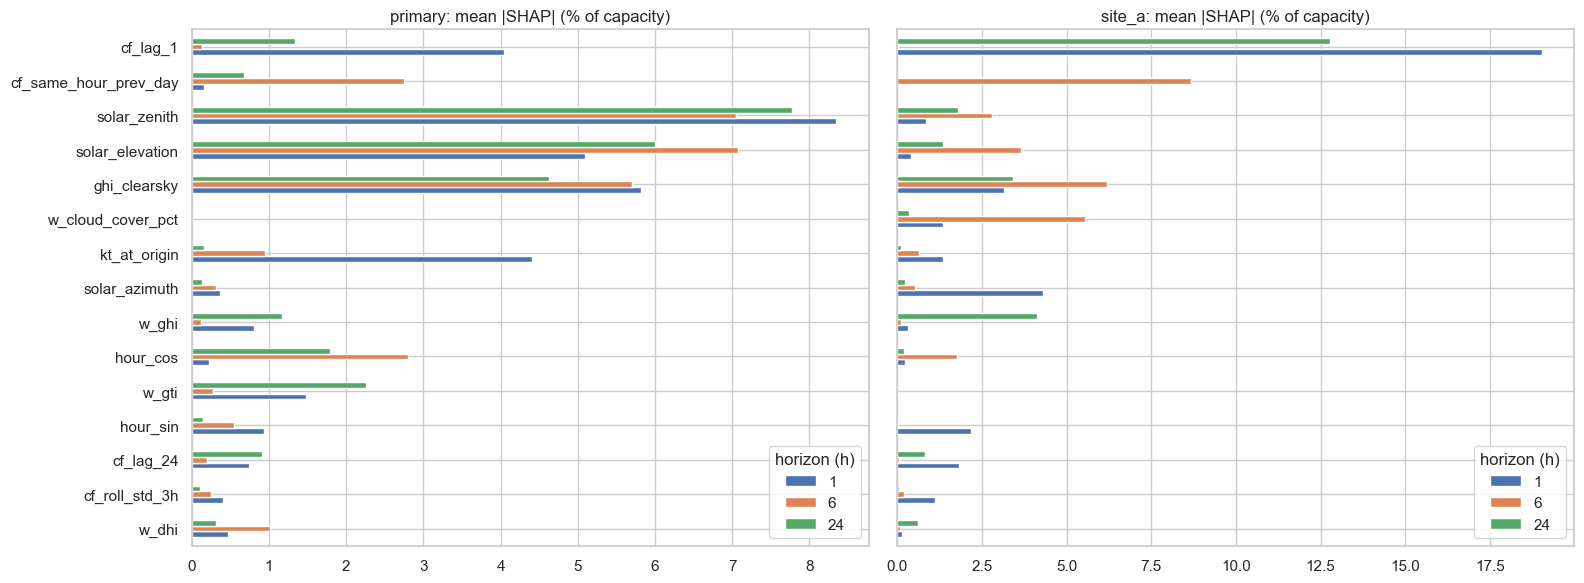

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for i, s in enumerate(data):
    (imp.loc[top[::-1], s] * 100).plot.barh(ax=ax[i])
    ax[i].set_title(f"{s}: mean |SHAP| (% of capacity)"); ax[i].legend(title="horizon (h)")
fig.tight_layout(); fig.savefig(FIG / "15_shap_importance.png", dpi=120); plt.show()

## 3. Direction of effects (beeswarm), h = 1 and h = 24

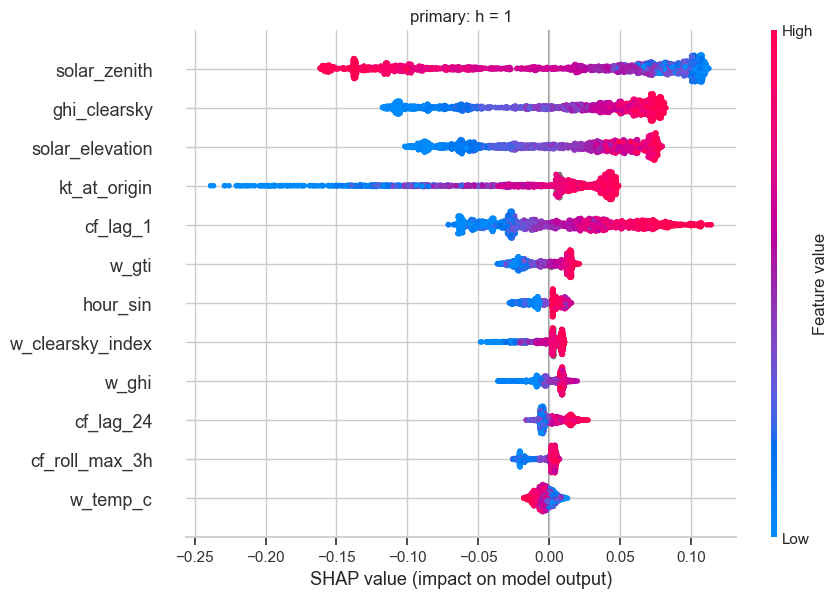

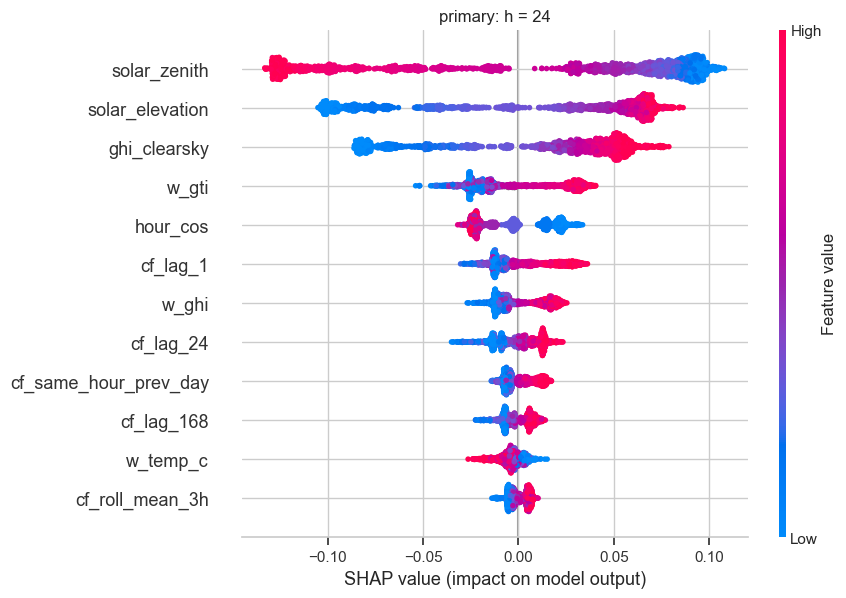

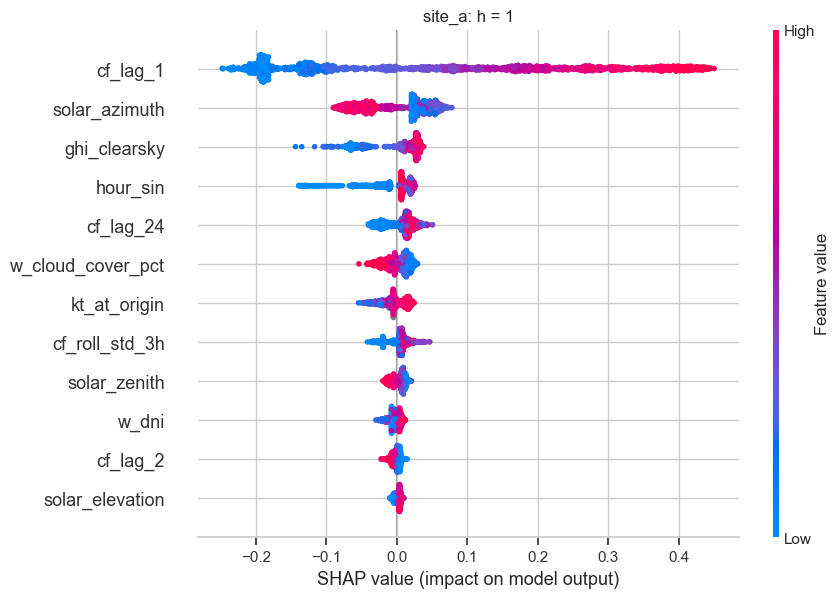

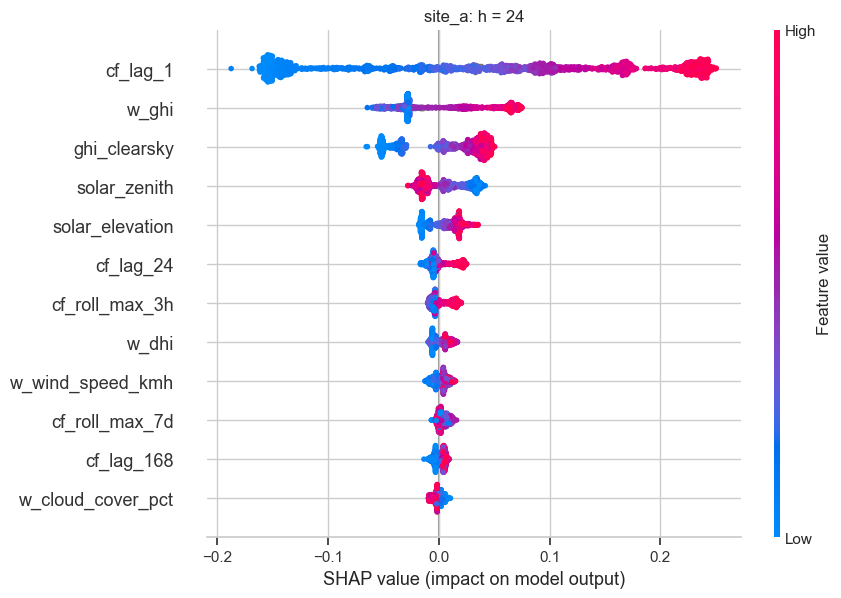

In [5]:
for s in data:
    for h in (1, 24):
        v, x = shap_store[(s, h)]
        shap.summary_plot(v, x, max_display=12, show=False, plot_size=(9, 6))
        plt.title(f"{s}: h = {h}")
        plt.savefig(FIG / f"16_shap_beeswarm_{s}_h{h}.png", dpi=120, bbox_inches="tight"); plt.show()

In [6]:
(imp * 100).round(4).to_csv(ROOT / "reports" / "shap_importance.csv")
print("saved reports/shap_importance.csv")

saved reports/shap_importance.csv


## Findings
1. **Short horizons rely on the latest output.** At h = 1 the largest contributor is CF at the origin (`cf_lag_1`). Its mean |SHAP| is 4 % of capacity on the primary site and **19 %** on Site A, where cloudy weather makes the most recent hour the best guide.
2. **On the sunny primary site, sun geometry dominates at every horizon.** Solar zenith/elevation and clear-sky GHI together contribute about 6–8 % of capacity each. The model mostly learns the clear-sky curve and then corrects it with recent output.
3. **The model switches inputs as the horizon grows.** At h = 6 the latest output is almost useless (≤ 0.14 %), so the model uses the same hour yesterday (`cf_same_hour_prev_day`, 8.7 % on Site A) and the hour of day instead. At h = 24 the origin *is* the same hour yesterday, so `cf_lag_1` returns.
4. **Cloud cover matters at Site A** (up to 5.5 % at h = 6), even though only the value at origin is used. This supports RQ3/RQ6: a cloud-cover *forecast* is the obvious next input.
5. The clear-sky index at origin (`kt_at_origin`) matters at h = 1 (4.4 % primary) but fades by 24 h, as expected.